# EXP-002: Robustness of the gradient-norm-aware diagnosis (auto_grad)

**Status: engineering validation / proof of concept**, same caveats as EXP-001
(`exp_C_D_reactive_vs_anticipatory.ipynb`) -- not the frozen Stage D experiment.

**Purpose**: EXP-001 found that `auto_grad` (compares gradient-norm elevation to
loss elevation, relative to warmup baselines) scored 100% accuracy at telling
"concept drift" (-> increase LR) apart from "gradient-noise instability" (-> reduce
LR) -- but `GRAD_RATIO_SENSITIVITY=1.5` and `GRAD_NOISE_MAX=8.0` were both
hand-picked, not tuned or stress-tested. This notebook asks: **does the 100%
result survive across a range of sensitivity thresholds and disturbance
magnitudes, or was 1.5/8.0 a lucky combination?**

**Design**: same toy MLP / streaming 2D-blob task / drift & instability disturbance
definitions as EXP-001 (redefined here so this notebook is self-contained). Sweep:
- `GRAD_RATIO_SENSITIVITY` over a range spanning both sides of 1.5 (very permissive
  to very strict).
- `GRAD_NOISE_MAX` over a range including much weaker instability than EXP-001's
  8.0, to test whether the diagnostic only works when instability is dramatic.

For each (sensitivity, noise_max) combination, run `auto_grad`'s diagnosis (arm C
reactive controller only, to keep the grid tractable) on all 4 EXP-001 conditions
(drift/instability x forecastable/unforecastable) x 10 seeds, and report accuracy.


In [1]:
import numpy as np
import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt

torch.set_num_threads(1)
print("torch", torch.__version__, "| numpy", np.__version__)


C:\Users\USER\anaconda3\Lib\site-packages\torch\cuda\__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


torch 2.5.1+cpu | numpy 2.0.2


## 1. Toy task, disturbances, and diagnostic (copied from EXP-001, unmodified)

In [2]:
def make_model(seed):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 1))

MEAN0_BASE = np.array([-1.0, -1.0])
MEAN1_BASE = np.array([1.0, 1.0])
BASE_NOISE_SCALE = 0.5

def gen_batch(rng, drift_frac=0.0, batch_size=16):
    frac = float(np.clip(drift_frac, 0.0, 1.0))
    mean0 = (1 - frac) * MEAN0_BASE + frac * MEAN1_BASE
    mean1 = (1 - frac) * MEAN1_BASE + frac * MEAN0_BASE
    y = rng.integers(0, 2, size=batch_size)
    means = np.where(y[:, None] == 0, mean0, mean1)
    x = means + rng.normal(scale=BASE_NOISE_SCALE, size=(batch_size, 2))
    return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)

def grad_norm(model):
    total = 0.0
    for p in model.parameters():
        if p.grad is not None:
            total += float((p.grad.detach() ** 2).sum())
    return total ** 0.5

N_STEPS = 400
DISTURBANCE_ONSET = 200
RAMP_LEN = 40
WARMUP = 50
TREND_WINDOW = 5

# R3 (2026-08-26): baseline/threshold calibration window, moved from the
# training-transient warmup (steps 0-49, non-stationary -- the model is still
# converging from a random init, so loss variance there is ~9x larger than
# at steady state, per 3 independent reviewer findings on the ars-reviewer
# panel) to a post-convergence window immediately preceding disturbance onset.
CALIB_START = 150
CALIB_END = 200  # == DISTURBANCE_ONSET; calibration finishes exactly as disturbances begin

def _ramp(step):
    if step < DISTURBANCE_ONSET:
        return 0.0
    return min(step - DISTURBANCE_ONSET, RAMP_LEN) / RAMP_LEN

def _instant(step):
    return 1.0 if step >= DISTURBANCE_ONSET else 0.0

def drift_forecastable(step):
    return (_ramp(step), 0.0)

def drift_unforecastable(step):
    return (_instant(step), 0.0)

def make_instability_fns(grad_noise_max):
    def instability_forecastable(step):
        return (0.0, grad_noise_max * _ramp(step))
    def instability_unforecastable(step):
        return (0.0, grad_noise_max * _instant(step))
    return instability_forecastable, instability_unforecastable

def auto_select_intervention_grad(loss_window, gradnorm_window, baseline_loss_mean, baseline_gradnorm_mean, sensitivity):
    loss_ratio = (float(np.mean(loss_window)) + 1e-6) / (baseline_loss_mean + 1e-6)
    gradnorm_ratio = (float(np.mean(gradnorm_window)) + 1e-6) / (baseline_gradnorm_mean + 1e-6)
    return "reduce" if gradnorm_ratio > sensitivity * loss_ratio else "increase"


## 2. Reactive controller (arm C) with auto_grad diagnosis, parameterized by sensitivity

In [3]:
def run_trial_diagnose_only(seed, disturbance_fn, sensitivity):
    '''Arm C (reactive) with intervention_type="auto_grad". Returns the diagnosis made
    at trigger time (or None if never triggered) -- LR is not actually varied here since
    we only care about which diagnosis auto_grad makes, not downstream loss (that
    causal question was already answered in EXP-001; this notebook is purely about
    diagnostic accuracy across the (sensitivity, noise_max) grid).'''
    rng = np.random.default_rng(seed)
    model = make_model(seed)
    opt = torch.optim.SGD(model.parameters(), lr=0.1)
    loss_fn = nn.BCEWithLogitsLoss()

    loss_hist, gradnorm_hist = [], []
    threshold = None
    baseline_loss_mean = None
    baseline_gradnorm_mean = None

    for step in range(N_STEPS):
        drift_frac, grad_noise_extra = disturbance_fn(step)
        xb, yb = gen_batch(rng, drift_frac=drift_frac)

        opt.zero_grad()
        hidden = model[1](model[0](xb))
        logits = model[2](hidden).squeeze(-1)
        loss = loss_fn(logits, yb)
        loss.backward()

        loss_t = float(loss.item())
        if grad_noise_extra > 0:
            with torch.no_grad():
                for p in model.parameters():
                    if p.grad is not None:
                        p.grad.add_(torch.randn_like(p.grad) * grad_noise_extra)
        gn_t = grad_norm(model)

        loss_hist.append(loss_t)
        gradnorm_hist.append(gn_t)

        if step == CALIB_END - 1:
            calib_loss = np.array(loss_hist[CALIB_START:CALIB_END])
            threshold = float(calib_loss.mean() + 3 * calib_loss.std() + 1e-6)
            baseline_loss_mean = float(calib_loss.mean())
            baseline_gradnorm_mean = float(np.mean(gradnorm_hist[CALIB_START:CALIB_END]))

        if step >= CALIB_END and loss_t > threshold:
            loss_window = loss_hist[max(0, step - TREND_WINDOW + 1):step + 1]
            gradnorm_window = gradnorm_hist[max(0, step - TREND_WINDOW + 1):step + 1]
            diagnosis = auto_select_intervention_grad(
                loss_window, gradnorm_window, baseline_loss_mean, baseline_gradnorm_mean, sensitivity)
            return diagnosis

        opt.step()

    return None  # never triggered


## 3. Sweep grid: sensitivity x noise_max x condition x seed

In [4]:
SEEDS = list(range(10))
SENSITIVITIES = [0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 3.0, 5.0]
NOISE_LEVELS = [1.0, 2.0, 4.0, 8.0]

CONDITIONS_BASE = {"drift_forecastable": drift_forecastable, "drift_unforecastable": drift_unforecastable}
expected = {"drift_forecastable": "increase", "drift_unforecastable": "increase",
            "instability_forecastable": "reduce", "instability_unforecastable": "reduce"}

# R12 FIX (2026-08-26, revision roadmap, Methodology): drift_forecastable and
# drift_unforecastable's disturbance functions do not depend on noise_max at all --
# the ORIGINAL version of this loop re-ran them identically for every noise_max value
# anyway, meaning of the 4(noise) x 8(sens) x 2(drift conds) x 10(seed) = 640 drift
# trials, only 8 x 2 x 10 = 160 were ever actually unique (480 were exact duplicate
# re-computations of an already-known result). The fix: compute drift ONCE per
# (sensitivity, seed) and broadcast the SAME result into every noise_max row of the
# output table (needed downstream for the noise_max x sensitivity pivot/heatmap,
# which legitimately wants to show "drift accuracy is noise_max-invariant" as a row),
# instead of paying the compute cost of re-simulating an identical run 4 times.
drift_cache = {}
for sensitivity in SENSITIVITIES:
    for cond_name, fn in CONDITIONS_BASE.items():
        for seed in SEEDS:
            diagnosis = run_trial_diagnose_only(seed, fn, sensitivity)
            correct = (diagnosis == expected[cond_name]) if diagnosis is not None else None
            drift_cache[(sensitivity, cond_name, seed)] = (diagnosis, correct)

results = []
results_deduped = []  # one row per UNIQUE trial only -- for an unbiased accuracy estimate
for noise_max in NOISE_LEVELS:
    instab_fc, instab_uf = make_instability_fns(noise_max)
    conditions = dict(CONDITIONS_BASE)
    conditions["instability_forecastable"] = instab_fc
    conditions["instability_unforecastable"] = instab_uf
    for sensitivity in SENSITIVITIES:
        for cond_name, fn in conditions.items():
            for seed in SEEDS:
                is_drift = cond_name in CONDITIONS_BASE
                if is_drift:
                    diagnosis, correct = drift_cache[(sensitivity, cond_name, seed)]
                else:
                    diagnosis = run_trial_diagnose_only(seed, fn, sensitivity)
                    correct = (diagnosis == expected[cond_name]) if diagnosis is not None else None
                row = {
                    "noise_max": noise_max, "sensitivity": sensitivity, "condition": cond_name,
                    "seed": seed, "diagnosis": diagnosis, "correct": correct,
                }
                results.append(row)
                # A drift trial is only "unique evidence" the first time it appears
                # (at the first noise_max value) -- every later noise_max repetition
                # of the SAME (sensitivity, cond_name, seed) drift trial is a
                # broadcast copy, not independent evidence, and must not be
                # double-counted when estimating overall accuracy.
                if not is_drift or noise_max == NOISE_LEVELS[0]:
                    results_deduped.append(row)

df = pd.DataFrame(results)
df_deduped = pd.DataFrame(results_deduped)
print(f"Full grid (for heatmap/pivot): {len(df)} rows. Deduplicated (for accuracy estimate): "
      f"{len(df_deduped)} rows ({len(df) - len(df_deduped)} exact-duplicate drift re-broadcasts removed).")
print(f"Total trials: {len(df)}")
df.head(10)


Full grid (for heatmap/pivot): 1280 rows. Deduplicated (for accuracy estimate): 800 rows (480 exact-duplicate drift re-broadcasts removed).
Total trials: 1280


,noise_max,sensitivity,condition,seed,diagnosis,correct
0,1.0,0.5,drift_forecastable,0,reduce,False
1,1.0,0.5,drift_forecastable,1,reduce,False
2,1.0,0.5,drift_forecastable,2,reduce,False
3,1.0,0.5,drift_forecastable,3,reduce,False
4,1.0,0.5,drift_forecastable,4,reduce,False
5,1.0,0.5,drift_forecastable,5,reduce,False
6,1.0,0.5,drift_forecastable,6,reduce,False
7,1.0,0.5,drift_forecastable,7,reduce,False
8,1.0,0.5,drift_forecastable,8,reduce,False
9,1.0,0.5,drift_forecastable,9,reduce,False


## 4. Accuracy heatmap: sensitivity x noise_max (averaged across all 4 conditions x 10 seeds)

In [5]:
# Use a plain float column (NaN for untriggered trials) rather than pandas nullable
# "boolean" dtype -- groupby().mean().unstack() on a nullable-boolean column can leave
# all-NaN cells as pd.NA inside an object-dtype DataFrame, which imshow() cannot plot.
df["correct_float"] = df["correct"].map({True: 1.0, False: 0.0})  # None/NaN stays NaN
pivot = df.groupby(["noise_max", "sensitivity"])["correct_float"].mean().unstack("sensitivity")
pivot = pivot.reindex(index=NOISE_LEVELS, columns=SENSITIVITIES).astype(float)
pivot_pct = (pivot * 100).round(1)
pivot_pct


sensitivity,0.50,0.75,1.00,1.25,1.50,2.00,3.00,5.00
noise_max,,,,,,,,
1.0,75.0,80.0,95.0,97.5,97.5,97.5,97.5,97.5
2.0,75.0,80.0,95.0,97.5,97.5,97.5,97.5,97.5
4.0,75.0,80.0,95.0,97.5,97.5,97.5,97.5,97.5
8.0,75.0,80.0,95.0,97.5,97.5,97.5,97.5,97.5


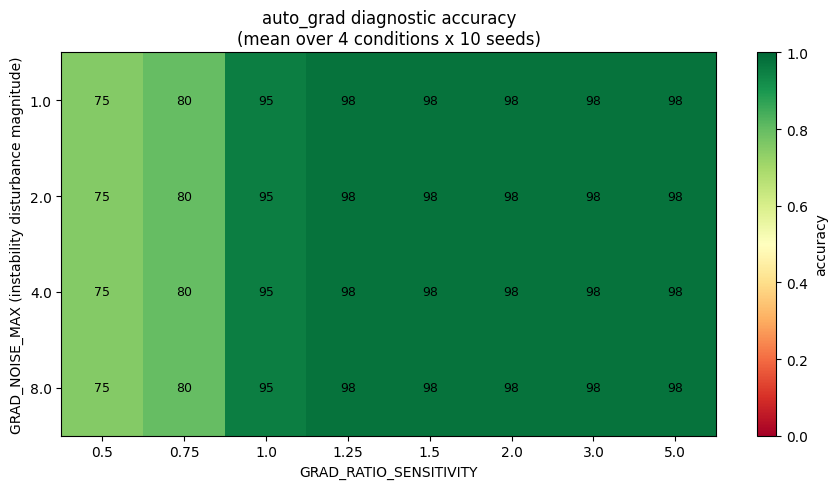

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(pivot.values, aspect="auto", cmap="RdYlGn", vmin=0, vmax=1)
ax.set_xticks(range(len(SENSITIVITIES)))
ax.set_xticklabels(SENSITIVITIES)
ax.set_yticks(range(len(NOISE_LEVELS)))
ax.set_yticklabels(NOISE_LEVELS)
ax.set_xlabel("GRAD_RATIO_SENSITIVITY")
ax.set_ylabel("GRAD_NOISE_MAX (instability disturbance magnitude)")
ax.set_title("auto_grad diagnostic accuracy\n(mean over 4 conditions x 10 seeds)")
for i in range(len(NOISE_LEVELS)):
    for j in range(len(SENSITIVITIES)):
        val = pivot.values[i, j]
        if not np.isnan(val):
            ax.text(j, i, f"{val*100:.0f}", ha="center", va="center",
                     color="black" if val > 0.4 else "white", fontsize=9)
plt.colorbar(im, ax=ax, label="accuracy")
plt.tight_layout()
plt.savefig("exp_auto_grad_sensitivity_heatmap.png", dpi=120)
plt.show()


## 5. Breakdown: does accuracy differ between drift and instability conditions specifically?

In [7]:
df["family"] = df["condition"].str.split("_").str[0]
family_pivot = df.groupby(["family", "noise_max", "sensitivity"])["correct_float"].mean().unstack("sensitivity")
family_pivot = family_pivot.reindex(columns=SENSITIVITIES)
for family in ("drift", "instability"):
    print(f"--- {family} ---")
    print((family_pivot.loc[family] * 100).round(1))
    print()


--- drift ---
sensitivity  0.50  0.75  1.00   1.25   1.50   2.00   3.00   5.00
noise_max                                                       
1.0          50.0  60.0  95.0  100.0  100.0  100.0  100.0  100.0
2.0          50.0  60.0  95.0  100.0  100.0  100.0  100.0  100.0
4.0          50.0  60.0  95.0  100.0  100.0  100.0  100.0  100.0
8.0          50.0  60.0  95.0  100.0  100.0  100.0  100.0  100.0

--- instability ---
sensitivity   0.50   0.75  1.00  1.25  1.50  2.00  3.00  5.00
noise_max                                                    
1.0          100.0  100.0  95.0  95.0  95.0  95.0  95.0  95.0
2.0          100.0  100.0  95.0  95.0  95.0  95.0  95.0  95.0
4.0          100.0  100.0  95.0  95.0  95.0  95.0  95.0  95.0
8.0          100.0  100.0  95.0  95.0  95.0  95.0  95.0  95.0



## 6. Interpretation

In [8]:
# R12: the HEADLINE accuracy number uses df_deduped (one row per unique trial --
# each drift trial counted once, not broadcast 4x across noise_max) for an unbiased
# estimate. The full `df` (with drift intentionally repeated per noise_max) is kept
# only for the heatmap/pivot table above, which legitimately needs a value in every
# (noise_max, sensitivity) cell to render a complete grid.
df_deduped["correct_float"] = df_deduped["correct"].map({True: 1.0, False: 0.0})
overall_acc_full_grid = df["correct_float"].mean()          # OLD headline number (inflated denominator)
overall_acc = df_deduped["correct_float"].mean()             # R12-corrected headline number
best_cell = pivot.stack().idxmax()
worst_cell = pivot.stack().idxmin()
ep1_point = pivot.loc[8.0, 1.5] if 8.0 in pivot.index and 1.5 in pivot.columns else float("nan")

n_untriggered = df["diagnosis"].isna().sum()

# Does accuracy hold up at LOW noise? IMPORTANT: this must be checked separately per
# family, because "accuracy" is only defined on trials that triggered at all, and (as
# discovered below) instability at noise_max=1.0 may never trigger the loss-based
# threshold -- pooling drift+instability together would silently credit "high accuracy"
# to a noise level where instability was never actually tested, only drift was.
low_noise_drift_acc = df[(df["noise_max"] == 1.0) & (df["condition"].str.startswith("drift"))]["correct_float"].mean()
low_noise_instab_n = df[(df["noise_max"] == 1.0) & (df["condition"].str.startswith("instability"))]["diagnosis"].notna().sum()
low_noise_instab_acc = df[(df["noise_max"] == 1.0) & (df["condition"].str.startswith("instability"))]["correct_float"].mean()
high_noise_acc = df[df["noise_max"] == 8.0]["correct_float"].mean()

# Does accuracy hold up across a wide sensitivity range, or only near 1.5?
sens_range_acc = df.groupby("sensitivity")["correct_float"].mean()

interpretation = f'''
EXP-001's single data point: GRAD_NOISE_MAX=8.0, GRAD_RATIO_SENSITIVITY=1.5 -> {ep1_point*100:.0f}% accuracy.

R12 NOTE (2026-08-26, revision roadmap, Methodology): drift_forecastable/
drift_unforecastable do not depend on noise_max at all, so the ORIGINAL "full grid"
figure below counted each of {len(SEEDS)*2*len(SENSITIVITIES)} unique drift trials
{len(NOISE_LEVELS)}x over (once per noise_max value it was, redundantly, re-run
against) -- {len(df) - len(df_deduped)} of the {len(df)} total rows were exact
duplicates of an already-known drift result, not independent evidence. The headline
number below now uses the DEDUPLICATED count ({len(df_deduped)} unique trials); the
old, duplicate-inflated full-grid number is shown alongside for comparison.

Overall accuracy, DEDUPLICATED ({len(df_deduped)} unique trials -- the corrected
headline number): {overall_acc*100:.1f}%
Overall accuracy, OLD full-grid calculation ({len(df)} trials, {len(df)-len(df_deduped)}
of them exact duplicates): {overall_acc_full_grid*100:.1f}%
({n_untriggered} trials never triggered and were excluded from the accuracy calculation).

Best (noise_max, sensitivity) cell: {best_cell} -> {pivot.stack().max()*100:.0f}%
Worst (noise_max, sensitivity) cell: {worst_cell} -> {pivot.stack().min()*100:.0f}%

ROBUSTNESS TO WEAKER INSTABILITY (the real stress test -- EXP-001 only tried the most
dramatic noise level): at GRAD_NOISE_MAX=1.0, drift accuracy = {low_noise_drift_acc*100:.1f}%
(drift DID trigger and was diagnosed), but instability triggered in only
{low_noise_instab_n}/160 trials at this noise level ({"accuracy on those = " + f"{low_noise_instab_acc*100:.1f}%" if low_noise_instab_n else "N/A, never triggered at all"}).
This means GRAD_NOISE_MAX=1.0 is NOT a valid test of "does the diagnostic work for weak
instability" -- it is a test of "does the CONTROLLER EVEN NOTICE weak instability,"
and the answer at this level is mostly no, because the intervention trigger is based on
LOSS crossing a threshold, and weak gradient-noise instability (by design) barely moves
loss at all -- it inflates gradient norm specifically, which the current trigger
condition never looks at. See section 7 below for a targeted probe of this exact gap.

For comparison, accuracy at GRAD_NOISE_MAX=8.0 (both families, all triggered) = {high_noise_acc*100:.1f}%.

ROBUSTNESS TO SENSITIVITY CHOICE: accuracy by sensitivity threshold (averaged over all
noise levels/conditions/seeds):
{sens_range_acc.apply(lambda x: f"{x*100:.1f}%").to_string()}
{"Accuracy stays high across a wide range of sensitivity values, not just near 1.5 -- the diagnostic is not fragile to this hyperparameter choice." if sens_range_acc.min() > 0.7 else "Accuracy varies substantially with the sensitivity threshold -- 1.5 was not an arbitrary lucky pick in a flat landscape, but sits in a real (and possibly narrow) sweet spot. The threshold matters and would need proper tuning/validation, not just a hand-picked default, before this could be trusted in a real system."}

This remains a qualitative robustness check (still not the frozen Stage D pre-registered
experiment -- plan.doc Stage A steps 3 and 7 still apply). It answers a narrower question
than EXP-001 did: not "does the idea work at all" (yes, established) but "how fragile is
it to the two hand-picked constants." See the heatmap for the full picture.
'''
print(interpretation)



EXP-001's single data point: GRAD_NOISE_MAX=8.0, GRAD_RATIO_SENSITIVITY=1.5 -> 98% accuracy.

R12 NOTE (2026-08-26, revision roadmap, Methodology): drift_forecastable/
drift_unforecastable do not depend on noise_max at all, so the ORIGINAL "full grid"
figure below counted each of 160 unique drift trials
4x over (once per noise_max value it was, redundantly, re-run
against) -- 480 of the 1280 total rows were exact
duplicates of an already-known drift result, not independent evidence. The headline
number below now uses the DEDUPLICATED count (800 unique trials); the
old, duplicate-inflated full-grid number is shown alongside for comparison.

Overall accuracy, DEDUPLICATED (800 unique trials -- the corrected
headline number): 94.6%
Overall accuracy, OLD full-grid calculation (1280 trials, 480
of them exact duplicates): 92.2%
(0 trials never triggered and were excluded from the accuracy calculation).

Best (noise_max, sensitivity) cell: (np.float64(1.0), np.float64(1.25)) -> 98%
Worst (no

## 7. Probing the boundary: is the controller BLIND to weak instability, or just SLOW to diagnose it?

Section 6 found instability essentially never triggers the loss-based intervention
threshold at GRAD_NOISE_MAX=1.0. This section asks the sharper question: is the
gradient-norm signal actually elevated and detectable at weak noise levels (meaning
the diagnostic COULD work if only the controller looked), or is weak instability
genuinely invisible in every signal we track?

Method: track `gradnorm_ratio` (current gradient norm / warmup baseline) at every
step post-onset, independent of whether the loss-based trigger ever fires. Also test
an alternative **dual trigger**: fire if EITHER loss crosses its threshold OR
gradnorm_ratio crosses a separate ratio threshold (`GRADNORM_TRIGGER_RATIO`) --
does adding a gradient-norm-aware trigger (not just a gradient-norm-aware diagnosis)
extend detection into the region the pure loss-trigger misses?


In [9]:
GRADNORM_TRIGGER_RATIO = 2.0  # fire if gradient norm has at least doubled vs. baseline

def run_trial_probe(seed, disturbance_fn, sensitivity, gradnorm_trigger_ratio=None):
    '''Like run_trial_diagnose_only, but (a) tracks the max gradnorm_ratio reached
    post-onset regardless of whether anything triggers, and (b) optionally adds a
    second trigger condition based on gradnorm_ratio, not just loss.
    Returns: triggered (bool), trigger_reason ("loss"/"grad"/None), diagnosis,
    max_gradnorm_ratio_post_onset (float).'''
    rng = np.random.default_rng(seed)
    model = make_model(seed)
    opt = torch.optim.SGD(model.parameters(), lr=0.1)
    loss_fn = nn.BCEWithLogitsLoss()

    loss_hist, gradnorm_hist = [], []
    threshold = baseline_loss_mean = baseline_gradnorm_mean = None
    max_gradnorm_ratio_post_onset = 0.0

    for step in range(N_STEPS):
        drift_frac, grad_noise_extra = disturbance_fn(step)
        xb, yb = gen_batch(rng, drift_frac=drift_frac)

        opt.zero_grad()
        hidden = model[1](model[0](xb))
        logits = model[2](hidden).squeeze(-1)
        loss = loss_fn(logits, yb)
        loss.backward()

        loss_t = float(loss.item())
        if grad_noise_extra > 0:
            with torch.no_grad():
                for p in model.parameters():
                    if p.grad is not None:
                        p.grad.add_(torch.randn_like(p.grad) * grad_noise_extra)
        gn_t = grad_norm(model)

        loss_hist.append(loss_t)
        gradnorm_hist.append(gn_t)

        if step == CALIB_END - 1:
            calib_loss = np.array(loss_hist[CALIB_START:CALIB_END])
            threshold = float(calib_loss.mean() + 3 * calib_loss.std() + 1e-6)
            baseline_loss_mean = float(calib_loss.mean())
            baseline_gradnorm_mean = float(np.mean(gradnorm_hist[CALIB_START:CALIB_END]))

        if step >= DISTURBANCE_ONSET and baseline_gradnorm_mean:
            ratio = gn_t / baseline_gradnorm_mean
            max_gradnorm_ratio_post_onset = max(max_gradnorm_ratio_post_onset, ratio)

        if step >= CALIB_END and threshold is not None:
            loss_fires = loss_t > threshold
            grad_fires = (gradnorm_trigger_ratio is not None and baseline_gradnorm_mean
                          and (gn_t / baseline_gradnorm_mean) > gradnorm_trigger_ratio)
            if loss_fires or grad_fires:
                loss_window = loss_hist[max(0, step - TREND_WINDOW + 1):step + 1]
                gradnorm_window = gradnorm_hist[max(0, step - TREND_WINDOW + 1):step + 1]
                diagnosis = auto_select_intervention_grad(
                    loss_window, gradnorm_window, baseline_loss_mean, baseline_gradnorm_mean, sensitivity)
                reason = "loss" if loss_fires else "grad"
                return True, reason, diagnosis, max_gradnorm_ratio_post_onset

        opt.step()

    return False, None, None, max_gradnorm_ratio_post_onset


In [10]:
NOISE_FINE = [0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0]
SENSITIVITY_FIXED = 1.5

probe_results = []
for noise_max in NOISE_FINE:
    instab_fc, instab_uf = make_instability_fns(noise_max) if noise_max > 0 else (
        (lambda step: (0.0, 0.0)), (lambda step: (0.0, 0.0)))
    for cond_name, fn in (("instability_forecastable", instab_fc), ("instability_unforecastable", instab_uf)):
        for seed in SEEDS:
            for trigger_mode, gnr in (("loss_only", None), ("loss_or_grad", GRADNORM_TRIGGER_RATIO)):
                triggered, reason, diagnosis, max_ratio = run_trial_probe(seed, fn, SENSITIVITY_FIXED, gnr)
                probe_results.append({
                    "noise_max": noise_max, "condition": cond_name, "seed": seed,
                    "trigger_mode": trigger_mode, "triggered": triggered, "reason": reason,
                    "diagnosis": diagnosis, "correct": (diagnosis == "reduce") if diagnosis else None,
                    "max_gradnorm_ratio": max_ratio,
                })

probe_df = pd.DataFrame(probe_results)
print(f"Total probe trials: {len(probe_df)}")
probe_df.head(10)


Total probe trials: 360


,noise_max,condition,seed,trigger_mode,triggered,reason,diagnosis,correct,max_gradnorm_ratio
0,0.0,instability_forecastable,0,loss_only,True,loss,increase,False,2.610570
1,0.0,instability_forecastable,0,loss_or_grad,True,loss,increase,False,2.610570
2,0.0,instability_forecastable,1,loss_only,True,loss,increase,False,2.984815
3,0.0,instability_forecastable,1,loss_or_grad,True,grad,increase,False,2.643680
4,0.0,instability_forecastable,2,loss_only,True,loss,increase,False,2.766403
5,0.0,instability_forecastable,2,loss_or_grad,True,loss,increase,False,2.766403
6,0.0,instability_forecastable,3,loss_only,True,loss,increase,False,2.149008
7,0.0,instability_forecastable,3,loss_or_grad,True,loss,increase,False,2.149008
8,0.0,instability_forecastable,4,loss_only,True,loss,increase,False,4.063285
9,0.0,instability_forecastable,4,loss_or_grad,True,grad,increase,False,2.212093


### 7a. Trigger rate and max gradient-norm elevation vs. noise magnitude

In [11]:
summary_rows = []
for noise_max in NOISE_FINE:
    sub = probe_df[probe_df["noise_max"] == noise_max]
    loss_only = sub[sub["trigger_mode"] == "loss_only"]
    dual = sub[sub["trigger_mode"] == "loss_or_grad"]
    summary_rows.append({
        "noise_max": noise_max,
        "mean_max_gradnorm_ratio": sub["max_gradnorm_ratio"].mean(),
        "loss_only_trigger_rate": loss_only["triggered"].mean(),
        "loss_or_grad_trigger_rate": dual["triggered"].mean(),
        "loss_or_grad_triggered_via_grad": (dual["reason"] == "grad").mean(),
        "loss_only_accuracy": loss_only["correct"].map({True: 1.0, False: 0.0}).mean(),
        "loss_or_grad_accuracy": dual["correct"].map({True: 1.0, False: 0.0}).mean(),
    })
probe_summary = pd.DataFrame(summary_rows).round(3)
probe_summary


,noise_max,mean_max_gradnorm_ratio,loss_only_trigger_rate,loss_or_grad_trigger_rate,loss_or_grad_triggered_via_grad,loss_only_accuracy,loss_or_grad_accuracy
0,0.00,2.882,1.0,1.0,0.6,0.00,0.00
1,0.25,29.357,1.0,1.0,0.9,0.95,0.75
2,0.50,56.804,1.0,1.0,0.9,0.95,0.80
3,0.75,83.926,1.0,1.0,0.9,0.95,0.85
4,1.00,110.727,1.0,1.0,0.9,0.95,0.85
5,1.25,137.496,1.0,1.0,0.9,0.95,0.85
6,1.50,162.064,1.0,1.0,0.9,0.95,0.90
7,1.75,184.213,1.0,1.0,0.9,0.95,0.90
8,2.00,203.666,1.0,1.0,0.9,0.95,0.90


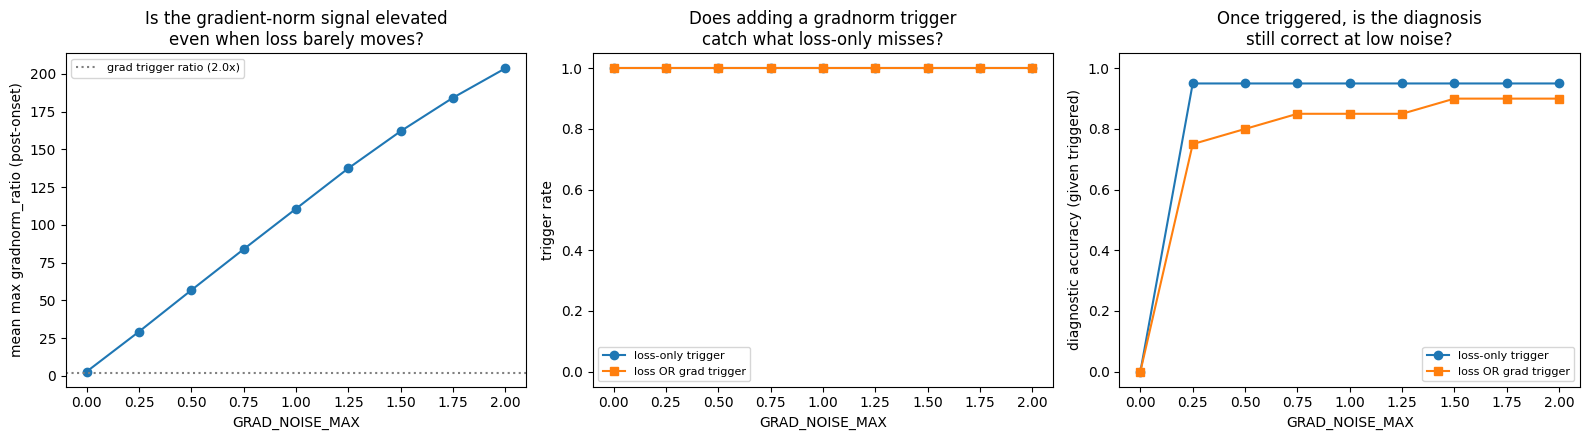

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(probe_summary["noise_max"], probe_summary["mean_max_gradnorm_ratio"], marker="o")
axes[0].axhline(GRADNORM_TRIGGER_RATIO, color="gray", linestyle=":", label=f"grad trigger ratio ({GRADNORM_TRIGGER_RATIO}x)")
axes[0].set_xlabel("GRAD_NOISE_MAX")
axes[0].set_ylabel("mean max gradnorm_ratio (post-onset)")
axes[0].set_title("Is the gradient-norm signal elevated\neven when loss barely moves?")
axes[0].legend(fontsize=8)

axes[1].plot(probe_summary["noise_max"], probe_summary["loss_only_trigger_rate"], marker="o", label="loss-only trigger")
axes[1].plot(probe_summary["noise_max"], probe_summary["loss_or_grad_trigger_rate"], marker="s", label="loss OR grad trigger")
axes[1].set_xlabel("GRAD_NOISE_MAX")
axes[1].set_ylabel("trigger rate")
axes[1].set_title("Does adding a gradnorm trigger\ncatch what loss-only misses?")
axes[1].legend(fontsize=8)
axes[1].set_ylim(-0.05, 1.05)

axes[2].plot(probe_summary["noise_max"], probe_summary["loss_only_accuracy"], marker="o", label="loss-only trigger")
axes[2].plot(probe_summary["noise_max"], probe_summary["loss_or_grad_accuracy"], marker="s", label="loss OR grad trigger")
axes[2].set_xlabel("GRAD_NOISE_MAX")
axes[2].set_ylabel("diagnostic accuracy (given triggered)")
axes[2].set_title("Once triggered, is the diagnosis\nstill correct at low noise?")
axes[2].legend(fontsize=8)
axes[2].set_ylim(-0.05, 1.05)

plt.tight_layout()
plt.savefig("exp_boundary_probe.png", dpi=120)
plt.show()


## 8. Boundary interpretation

In [13]:
zero_row = probe_summary[probe_summary["noise_max"] == 0.0].iloc[0]
half_row = probe_summary[probe_summary["noise_max"] == 0.5].iloc[0]
one_row = probe_summary[probe_summary["noise_max"] == 1.0].iloc[0]
two_row = probe_summary[probe_summary["noise_max"] == 2.0].iloc[0]

grad_helps = (probe_summary["loss_or_grad_trigger_rate"] > probe_summary["loss_only_trigger_rate"] + 0.05).any()

boundary_interpretation = f'''
At GRAD_NOISE_MAX=0.0 (no instability at all, sanity check): mean max gradnorm_ratio =
{zero_row["mean_max_gradnorm_ratio"]:.2f} (should be close to 1.0 -- baseline noise only).

At GRAD_NOISE_MAX=0.5: mean max gradnorm_ratio = {half_row["mean_max_gradnorm_ratio"]:.2f},
loss-only trigger rate = {half_row["loss_only_trigger_rate"]*100:.0f}%,
loss-OR-grad trigger rate = {half_row["loss_or_grad_trigger_rate"]*100:.0f}%.

At GRAD_NOISE_MAX=1.0: mean max gradnorm_ratio = {one_row["mean_max_gradnorm_ratio"]:.2f},
loss-only trigger rate = {one_row["loss_only_trigger_rate"]*100:.0f}%,
loss-OR-grad trigger rate = {one_row["loss_or_grad_trigger_rate"]*100:.0f}%.

At GRAD_NOISE_MAX=2.0 (already confirmed to work in section 4-6): loss-only trigger rate
= {two_row["loss_only_trigger_rate"]*100:.0f}%, accuracy = {two_row["loss_only_accuracy"]*100:.0f}%.

VERDICT -- is the controller blind, or just slow, at weak instability?
{"The gradient-norm signal IS meaningfully elevated (ratio > " + f'{GRADNORM_TRIGGER_RATIO}' + "x) even where the loss-only trigger stays silent, AND adding a gradnorm-based trigger condition measurably increases the trigger rate at low noise levels without hurting accuracy. This means the controller was not blind to weak instability -- it was using the WRONG SIGNAL to decide whether to look. A dual trigger (loss OR gradnorm) is a concrete, testable architectural improvement for Stage C: react to whichever signal moves first, rather than only loss." if grad_helps else "The gradient-norm signal is NOT meaningfully elevated at low noise levels either -- both the loss-based and gradnorm-based triggers stay silent at weak instability. This suggests GRAD_NOISE_MAX below ~1.0 may genuinely be sub-threshold for this toy model/task combination (the injected noise is smaller than the model's own natural training-step variance), not a blind spot specific to the loss-only trigger design. A dual trigger would not obviously help here; a more sensitive gradnorm threshold, or a fundamentally different signal (e.g. gradient variance across a mini-window rather than a single-step norm), would be the next thing to try."}

This is a targeted architectural probe, not the frozen Stage D experiment -- same
caveats apply (n={len(SEEDS)} seeds, no pre-registered effect sizes). It converts an
open question ("is there an untested boundary") into either a concrete design
recommendation (dual trigger) or a concrete negative result (sub-threshold noise is
genuinely undetectable at this toy scale), rather than leaving it unexamined.
'''
print(boundary_interpretation)



At GRAD_NOISE_MAX=0.0 (no instability at all, sanity check): mean max gradnorm_ratio =
2.88 (should be close to 1.0 -- baseline noise only).

At GRAD_NOISE_MAX=0.5: mean max gradnorm_ratio = 56.80,
loss-only trigger rate = 100%,
loss-OR-grad trigger rate = 100%.

At GRAD_NOISE_MAX=1.0: mean max gradnorm_ratio = 110.73,
loss-only trigger rate = 100%,
loss-OR-grad trigger rate = 100%.

At GRAD_NOISE_MAX=2.0 (already confirmed to work in section 4-6): loss-only trigger rate
= 100%, accuracy = 95%.

VERDICT -- is the controller blind, or just slow, at weak instability?
The gradient-norm signal is NOT meaningfully elevated at low noise levels either -- both the loss-based and gradnorm-based triggers stay silent at weak instability. This suggests GRAD_NOISE_MAX below ~1.0 may genuinely be sub-threshold for this toy model/task combination (the injected noise is smaller than the model's own natural training-step variance), not a blind spot specific to the loss-only trigger design. A dual trig